# Installation

Follow the instructions [here](https://hackmd.io/8VOQUHNgTAugEBBwtZ91Sg#Setup)

# Setup

Go and sit in the root directory!

In [3]:
%cd ..

/home/tommonopoli/curvytron-rl


In [4]:
import threading
import curvytron
import matplotlib.pyplot as plt
from IPython.display import display, clear_output
import numpy as np

Start a curvytron server and point to its address. You have two options here:
1. Use a server already set up e.g. curvytron.com (N.B. Permission to use this server was kindly granted by Curvytron developer [@Tom32i](https://twitter.com/Tom32i). **Please do not abuse the server by spamming it with requests!**)
1. Setup and start your own server. The code is here: https://github.com/Curvytron/curvytron

If you're inside the Edinburgh University network, I normally have an instance running at the Informatics Forum at the address below (you need to be on the network to see it - you may need to [VPN in](http://computing.help.inf.ed.ac.uk/openvpn))

In [5]:
serveraddress = "127.0.0.1:8080"
serveraddress = "curvytron.com"

# Example Use

This instantiates a curvytron environment. A player called `name` will join a room called `room` on the specified server.

In [6]:
env = curvytron.CurvytronEnv(
    server=serveraddress, 
    room='test_room',
    name='random_boi',
    color='#ff0090'
    )

The below runs a random policy and plots the state at each timepoint. Since the player moves randomly, you may need to run this a few times to see trails, though you should always see a dot moving around before the player hits the edge.

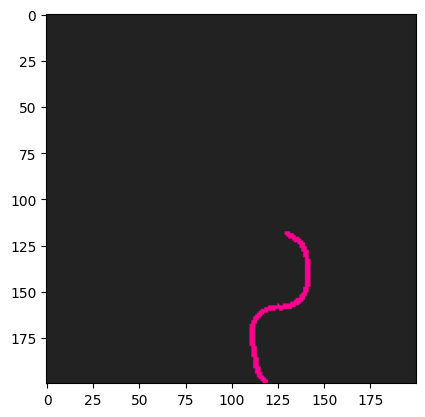

Angle=0.73, Position=(198.75, 118.125)
Episode finished after 37 steps


In [7]:
env.reset()
episode_over = False
steps = 0
while not episode_over:
    steps += 1
    action = np.random.choice(3)
    ob, r, episode_over = env.step(action)
    ax = plt.imshow(ob.pixels)
    print(f'Angle={ob.angle}, Position={ob.position}', end='\r')
    clear_output(wait=True)
    display(plt.gcf())
plt.close()
print(f'Angle={ob.angle}, Position={ob.position}')
print(f"Episode finished after {steps} steps")
#print(f"Killing player (Returns {env.client.join()})")

# The State Space

The valid actions are simply 0, 1, and 2, which are left, straight, and right respectively. The server will continue running the previously submitted action until a different action is given.

Let's observe the state that is returned when we call env.step(action), in the code above we saved it in `ob`. It is a tuple with three elements:
* angle - the angle clockwise from 3 o'clock, in radians, *not* modulo $2 \pi$ i.e. it just sums up and can be negative
* position - a matrix coordinate (x0, x1) describing the location of the head of your snake
* pixels - a 200 x 200 x 3 matrix representing the pixels in colour

In [35]:
ob

In [36]:
vars(ob).keys()

dict_keys(['angle', 'position', 'pixels'])

In [37]:
for kk in vars(ob):
    print('Attribute: curvytron.State.{}\n{}'.format(kk, 10*'='))
    display(type(vars(ob)[kk]))
    display(vars(ob)[kk])
    print('\n')
print(ob.pixels.shape)

Attribute: curvytron.State.angle


float

3.82



Attribute: curvytron.State.position


tuple

(21.287356321839077, 1.011494252873563)



Attribute: curvytron.State.pixels


numpy.ndarray

array([[[34, 34, 34],
        [34, 34, 34],
        [34, 34, 34],
        ...,
        [34, 34, 34],
        [34, 34, 34],
        [34, 34, 34]],

       [[34, 34, 34],
        [34, 34, 34],
        [34, 34, 34],
        ...,
        [34, 34, 34],
        [34, 34, 34],
        [34, 34, 34]],

       [[34, 34, 34],
        [34, 34, 34],
        [34, 34, 34],
        ...,
        [34, 34, 34],
        [34, 34, 34],
        [34, 34, 34]],

       ...,

       [[34, 34, 34],
        [34, 34, 34],
        [34, 34, 34],
        ...,
        [34, 34, 34],
        [34, 34, 34],
        [34, 34, 34]],

       [[34, 34, 34],
        [34, 34, 34],
        [34, 34, 34],
        ...,
        [34, 34, 34],
        [34, 34, 34],
        [34, 34, 34]],

       [[34, 34, 34],
        [34, 34, 34],
        [34, 34, 34],
        ...,
        [34, 34, 34],
        [34, 34, 34],
        [34, 34, 34]]], shape=(200, 200, 3), dtype=uint8)



(200, 200, 3)


# Starter Heuristic Agents

You'll find some code to get you started creating some agents by hand here: https://github.com/RyanrDavies/curvytron-client/blob/master/heuristic_agent.py.

All you need to extend the `Agent` class (found in `agent.py`) and implement the `action()` method, telling the agent how to behave with respect to the state it is passed in its `run()` method as the game plays. The code below imports some bots and executes each on a thread.

Calling `agent.start()` on an instantiated class (inherited from Agent) will make the agent join its room, indicate that it's ready, and send actions to the server when it is in the game.

**You can join their game and play against them!**

In [4]:
from heuristic_agent import RandomAgent, HeuristicAgent1, HeuristicAgent2, RaymanAgent

In [ ]:
room_name = 'another_room'  # if you get errors running this cell, there may already be a game
                         # in play with this name. Otherwise, check there are no threads running
                         # in the background by restarting the notebook
agents = [
    RandomAgent(server=serveraddress, room=room_name, name=f'RandomAgent'),
    HeuristicAgent1(server=serveraddress, room=room_name, name=f'HeuristicAgent1'),
    HeuristicAgent2(server=serveraddress, room=room_name, name=f'HeuristicAgent2'),
    RaymanAgent(server=serveraddress, room=room_name, name=f'RaymanAgent')
    ]

Go join the game yourself! **Tip**: If you just want to watch (and not play), join the room and click the x next to your player name.

In [ ]:
threads = []
for agent in agents:
    t = threading.Thread(target=agent.start())
    threads.append(t)
    t.start()

In [12]:
for agent in agents:
    agent.env.client.join()  # kills the agent

An example of gameplay:
<!-- ![Heuristic Agents](https://i.imgur.com/YM0m0zw.gif) -->
<img src="https://i.imgur.com/YM0m0zw.gif" >

## What now?

We've made a script for you to write your agent and quickly run it against our baseline agents. You'll find the script at: https://github.com/RyanrDavies/curvytron-client/blob/master/template_agent.py. You can run this script from the command line.

```
python template_agent.py -h
```

Use the help flag for information about the script call. This is probably the best way to work as we are using threads. It's easy to have threads running in the background without your realising.

You can also run tests from here if you like. Go fill out the [template](https://github.com/RyanrDavies/curvytron-client/blob/master/template_agent.py), import it, and play against some of our basic agents (or yourself!).

In [13]:
from template_agent import MyAgent 

In [ ]:
room_name = 'blahblahblah'
agents = [MyAgent(server=serveraddress, room=room_name, name='MyAgent_{}'.format(ii)) 
                for ii in range(2)]
agents += [HeuristicAgent1(server=serveraddress, room=room_name, name='HeuristicAgent1_{}'.format(ii)) 
                for ii in range(2)]
agents += [HeuristicAgent2(server=serveraddress, room=room_name, name='HeuristicAgent2_{}'.format(ii)) 
                for ii in range(2)]
agents += [RaymanAgent(server=serveraddress, room=room_name, name='RaymanAgent_{}'.format(ii)) 
                for ii in range(2)]

In [15]:
for agent in agents:
    agent.env.client.join()  # kills the agent